# Task span vs code-progress span — figures

Which span of the source run does the pivot read the goal from? (`scripts/diff/task_vs_progress_eval.py`,
`src/diff/task_vs_progress.py`; Qwen2.5-Coder-32B.)

Outputs → `notebooks/Figures/precommit_ablation/`.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
import figstyle as F
F.set_style()

MODEL = "Qwen2.5-Coder-32B-Instruct"
GROUP = "precommit_ablation"
DT = ["int", "str", "list[int]", "list[str]"]

{'ablate': ['prev_end', 'indent', 'var'], 'n_pad': 16, 'n_readout_heads': 122, 'steer_layer_range': [35, 46]}


## Task-span vs code-progress span

Source: `scripts/diff/task_vs_progress_eval.py` (`src/diff/task_vs_progress.py`). Python → Python, 4 datatypes × 32 = 128 per cell, causal-shift
only (oracle `claude-sonnet-4-6`, BOTH = miss). Each 2 × 2 grid fixes the intervention: rows = where the **task span**
(the task list + its closing `\n`) comes from, columns = where the **code-progress span** (`<|im_end|> … {var}`) comes from.
The top-left corner is the clean DST run.

- `tvp_residual_grid` — residual transfer (every layer + input embeddings; the span not transferred is pinned to clean DST). Fig 27 right panel.
- `tvp_kv_grids` — pivot-onwards KV transfer, 250 goal heads (top row) / all heads (bottom row) × V-boost 1, 2, 4.

In [8]:
# ── task-vs-progress: load the per-datatype summaries (the batch driver's <cache dir>.summary.json) ──
from matplotlib.colors import LinearSegmentedColormap
TVP_ROOT = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "notebook_caches", "task_vs_progress", MODEL)
TVP_DT = {"int": "int", "str": "str", "list[int]": "list_int", "list[str]": "list_str"}
TVP = {d: json.load(open(os.path.join(TVP_ROOT, f"{s}__python-python__seed1123__mx64__ro0__task+gap.summary.json")))
       for d, s in TVP_DT.items()}
assert all(v["n"] == 32 for s in TVP.values() for v in s.values()), "every config must have all 32 instances"

def tvp_name(method, heads, span, v):   # = src.diff.task_vs_progress.cfg_name
    return "clean DST (no-op)" if method == "none" else f"{method}{'·' + heads if heads else ''} · {span} · V×{v:g}"

def tvp_rate(name, dts=DT):   # pooled causal-shift (equal n per datatype -> mean of the cells)
    return float(np.mean([TVP[d][name]["causal_shift"] for d in dts]))

def tvp_grid(method, heads=None, v=1.0):
    # [[task DST · prog DST, task DST · prog SRC], [task SRC · prog DST, task SRC · prog SRC]]
    return np.array([[tvp_rate(tvp_name("none", None, "none", 1.0)), tvp_rate(tvp_name(method, heads, "progress", v))],
                     [tvp_rate(tvp_name(method, heads, "task", v)),  tvp_rate(tvp_name(method, heads, "task+progress", v))]])

# sequential single hue (the model colour), light -> dark; value labels on every cell
TVP_CMAP = LinearSegmentedColormap.from_list("tvp", ["#f3f7fb", F.MODEL_COLOR[MODEL]])          # KV transfer
TVP_CMAP_RES = LinearSegmentedColormap.from_list("tvp_res", ["#fbf3f2", "firebrick"])   # residual transfer

def draw_tvp_grid(ax, M, title=None, ticklabels=True, fontsize=11, cmap=None):
    ax.imshow(M, cmap=cmap or TVP_CMAP, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=fontsize,
                    color="white" if M[i, j] > 0.55 else "#1a1a1a")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    if ticklabels:
        ax.set_xticklabels(["DST", "SRC"]); ax.set_yticklabels(["DST", "SRC"])
        ax.set_xlabel("code-progress span from"); ax.set_ylabel("task span from")
    else:
        ax.set_xticklabels([]); ax.set_yticklabels([])
    ax.tick_params(which="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xticks([0.5], minor=True); ax.set_yticks([0.5], minor=True)
    ax.grid(which="minor", color="white", linewidth=3, alpha=1); ax.grid(which="major", visible=False)
    if title:
        ax.set_title(title, fontsize=10)

residual None     V×1
 [[0.   0.06]
 [0.89 0.98]]
kv       goal250  V×1
 [[0.   0.  ]
 [0.77 0.98]]
kv       goal250  V×2
 [[0.   0.04]
 [0.93 0.98]]
kv       goal250  V×4
 [[0.   0.26]
 [0.97 0.98]]
kv       all      V×1
 [[0.   0.06]
 [0.89 0.98]]
kv       all      V×2
 [[0.   0.16]
 [0.98 0.98]]
kv       all      V×4
 [[0.   0.38]
 [0.98 0.99]]


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/precommit_ablation/tvp_residual_grid.pdf


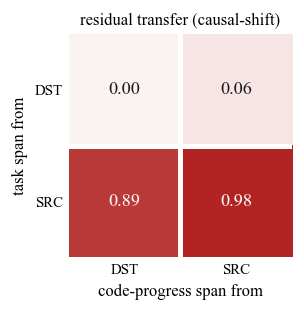

In [9]:
# ── Figure 27 (right panel): residual transfer, the 2 × 2 grid ──
fig, ax = plt.subplots(figsize=(2.9, 2.7))
draw_tvp_grid(ax, tvp_grid("residual"), title="residual transfer (causal-shift)", cmap=TVP_CMAP_RES)
fig.tight_layout()
print("saved", F.save_fig(fig, GROUP, "tvp_residual_grid")); plt.show()

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/precommit_ablation/tvp_kv_grids.pdf


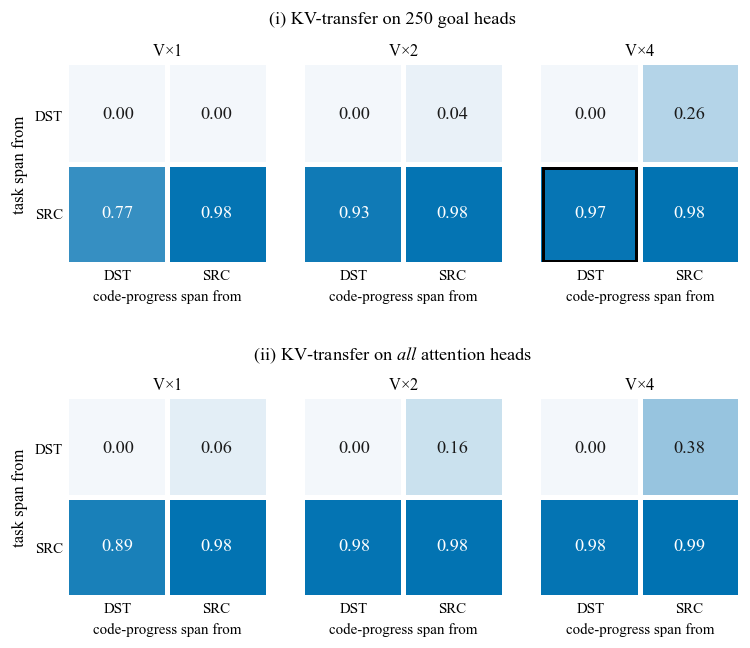

In [10]:
# ── KV transfer (pivot-onwards): (a) 250 goal heads / (b) all attention heads × V-boost 1, 2, 4 ──
ROWS = [("goal250", "(i) KV-transfer on 250 goal heads"), ("all", "(ii) KV-transfer on $all$ attention heads")]
VS = [1.0, 2.0, 4.0]
DEFAULT_KV = ("goal250", 4.0)   # boxed cell: the configuration reported in App I.1 (Fig 22 / Table 7)
fig = plt.figure(figsize=(7.2, 5.4))
subfigs = fig.subfigures(2, 1, hspace=0.06)
for sf, (h, rlab) in zip(subfigs, ROWS):
    sf.suptitle(rlab, fontsize=11)
    axes = sf.subplots(1, 3)
    for c, (ax, v) in enumerate(zip(axes, VS)):
        draw_tvp_grid(ax, tvp_grid("kv", h, v), title=f"V$\\times${v:g}", ticklabels=False)
        ax.set_xticklabels(["DST", "SRC"]); ax.set_yticklabels(["DST", "SRC"] if c == 0 else [])
        ax.set_xlabel("code-progress span from", fontsize=9)
        if c == 0: ax.set_ylabel("task span from")
        if (h, v) == DEFAULT_KV:
            BOX_AX = ax
fig.canvas.draw()
pt = BOX_AX.get_window_extent().width / 2 / (fig.dpi / 72)   # points per data unit (2 cells across)
lw, gap = 1.8, 3 / 2                                          # border width; half the white cell gap (grid linewidth 3)
o, i = (lw / 2) / pt, (gap + lw / 2) / pt                     # inset at the outer image edge / at the cell gap
# boxed cell = row 1 (task from SRC), col 0 (progress from DST): x in [-0.5, 0.5], y in [0.5, 1.5]
BOX_AX.add_patch(plt.Rectangle((-0.5 + o, 0.5 + i), 1 - o - i, 1 - o - i, fill=False, edgecolor="black",
                               linewidth=lw, joinstyle="miter", zorder=5))
print("saved", F.save_fig(fig, GROUP, "tvp_kv_grids")); plt.show()